# End-to-End Master Showcase: Multi-Asset VaR & ES Engine with Backtesting and Derivatives Revaluation
**USD 10,000,000 Macro Trading Desk Across Equity (`SPY`, `AAPL`), Rates (`TLT`), FX (`FXE`), and Commodity (`GLD`) Risk Factors**

### Executive Overview (4-Phase Walkthrough)
This self-contained master notebook runs the entire 4-phase quantitative market risk framework end-to-end:
1. **Phase 1 — Data & Multi-Asset Risk Factors (Equities, Rates, FX, Gold):** Ingesting, cleaning, and verifying stationarity (ADF) and leptokurtic stylized facts across both the 4-asset core book and the 5-asset FX-inclusive macro book (`SPY`, `AAPL`, `TLT`, `FXE`, `GLD`).
2. **Phase 2 — VaR & Expected Shortfall Engine (Including Asymmetric $\text{EGARCH}(1,1)$ Filtered Historical Simulation):** Comparing Plain Historical Simulation, Parametric Variance-Covariance, Cholesky Monte Carlo, and **$\text{EGARCH}(1,1)$ Filtered Historical Simulation (FHS)** (drawing on asymmetric log-volatility modeling from Master's thesis research).
3. **Phase 3 — Out-of-Sample Statistical Backtesting (1,500 Days):** Counting exceptions, applying **Basel Traffic-Light zones**, and running **Kupiec POF ($LR_{UC}$)** and **Christoffersen Markov Independence ($LR_{IND}, LR_{CC}$)** tests to prove why static/Gaussian models fail and why **$\text{EGARCH}(1,1)$ FHS** and **Hull-White VWHS** pass.
4. **Phase 4 — Derivatives Revaluation (Options + 5Y Interest-Rate Swap) & Stressed VaR ($\text{sVaR}$):** Pricing an `SPY` options portfolio and a $\$5,000,000$ 5-Year Pay-Fixed Interest-Rate Swap via Black-Scholes, discount curves, and Monte Carlo; demonstrating where Delta-Normal / DV01 and Delta-Gamma approximations break down relative to Full Revaluation; and comparing **Stressed VaR ($\text{sVaR}_{0.99}$)** over the 2020 COVID and 2022 Rate-Hike stress windows against the 2017 normal period.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path("/Users/mukundankit/Documents/Finance/market_risk_modelling")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_config, prepare_and_save_processed_data, compute_portfolio_returns
from src.eda_diagnostics import run_adf_stationarity_table, compute_stylized_facts_table
from src.var_estimators import build_phase1_comparison_table, compute_pretrade_marginal_var_sizing
from src.volatility_models import build_dynamic_var_series
from src.backtesting import run_champion_challenger_backtest
from src.derivatives_stress import (
    compare_derivative_var_approaches,
    evaluate_swap_approximation_breakdown,
    compute_stressed_var_comparison,
    build_2d_stress_vulnerability_grid,
)

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (13.5, 5.2)
plt.rcParams["figure.dpi"] = 120

cfg = load_config()
bundle = prepare_and_save_processed_data(cfg)
arith_returns = bundle["arith_returns"]
vix_df = bundle["vix"]
core_weights = cfg["portfolio"]["weights"]
fx_macro_weights = cfg["portfolio"]["multi_asset_fx_weights"]
notional_usd = float(cfg["portfolio"]["notional_usd"])

# Construct 5-Asset FX-Inclusive Macro Portfolio (Equity + Rates + FX + Gold)
fx_port_df = compute_portfolio_returns(arith_returns, weights=fx_macro_weights, notional_usd=notional_usd)
print("Core 4-Asset Weights (Equity/Rates/Gold):", core_weights)
print("Extended 5-Asset Weights (Equity/Rates/FX/Gold):", fx_macro_weights)

Core 4-Asset Weights (Equity/Rates/Gold): {'SPY': 0.3, 'AAPL': 0.2, 'TLT': 0.3, 'GLD': 0.2}
Extended 5-Asset Weights (Equity/Rates/FX/Gold): {'SPY': 0.3, 'AAPL': 0.15, 'TLT': 0.25, 'FXE': 0.15, 'GLD': 0.15}


## Phase 1: Multi-Asset Risk Factors (Equities, Rates, FX & Gold) & Baseline VaR/ES

In [2]:
stylized_5asset = compute_stylized_facts_table(
    arith_returns[["SPY", "AAPL", "TLT", "FXE", "GLD"]],
    portfolio_returns=fx_port_df["portfolio_arith_return"],
)
stylized_5asset[[
    "Annualized_Return_pct", "Annualized_Vol_pct", "Skewness", "Excess_Kurtosis", "Total_Kurtosis", "Tail_Ratio_vs_Normal", "Jarque_Bera_Stat"
]].round(3)

,Annualized_Return_pct,Annualized_Vol_pct,Skewness,Excess_Kurtosis,Total_Kurtosis,Tail_Ratio_vs_Normal,Jarque_Bera_Stat
Asset,,,,,,,
SPY,5.249,16.299,-0.532,16.927,19.927,5.825,33408.023
AAPL,12.173,25.460,-0.584,13.839,16.839,4.633,22401.426
TLT,-2.748,14.049,-0.267,8.560,11.560,4.633,8540.183
FXE,0.344,7.794,-0.117,3.894,6.894,5.692,1765.777
GLD,6.420,12.760,0.792,10.180,13.180,4.501,12326.767
PORTFOLIO,3.728,8.993,-0.532,7.393,10.393,6.487,6476.692


In [3]:
# Baseline 1-Day 95% & 99% VaR and ES Dashboard
phase1_tbl = build_phase1_comparison_table(arith_returns, bundle["portfolio"], weights=core_weights, notional_usd=notional_usd)
phase1_tbl[phase1_tbl["Confidence"] == "99%"].round(2)

,Estimator,Confidence,VaR_USD,VaR_pct_NAV,ES_USD,ES_pct_NAV,Bootstrap_SE_USD,CRO_VaR_Limit_Breach,CRO_ES_Limit_Breach
7,Historical Simulation (250d),99%,158473.92,1.58,173658.09,1.74,17724.11,False,False
8,Historical Simulation (500d),99%,136136.44,1.36,156722.50,1.57,11805.83,False,False
9,Parametric Normal (Var-Cov),99%,151353.73,1.51,173221.56,1.73,NaN,False,False
10,Parametric Lognormal,99%,150350.47,1.50,171836.34,1.72,NaN,False,False
11,Parametric Student-t (df=7.3),99%,164126.49,1.64,204959.07,2.05,NaN,False,False
12,Cornish-Fisher Semi-Parametric,99%,156793.80,1.57,185878.06,1.86,NaN,False,False
13,"Cholesky Monte Carlo (M=10,000)",99%,151617.06,1.52,173973.98,1.74,NaN,False,False


## Phase 2 & Phase 3: Asymmetric $\text{EGARCH}(1,1)$ Filtered Historical Simulation & 1,500-Day Validation Backtest
We estimate Nelson's (1991) **Asymmetric $\text{EGARCH}(1,1)$** model:
$$\ln(\sigma_t^2) = \omega + \alpha_1 \left(|z_{t-1}| - \mathbb{E}|z|\right) + \gamma_1 z_{t-1} + \beta_1 \ln(\sigma_{t-1}^2)$$
and scale the empirical standardized residuals $\hat{z}_{t-i} = (r_{t-i} - \hat{\mu})/\hat{\sigma}_{t-i}^{\text{EGARCH}}$ by the 1-step-ahead volatility forecast $\hat{\sigma}_{T \mid T-1}^{\text{EGARCH}}$ to produce the **$\text{EGARCH}(1,1)$ Filtered Historical Simulation (FHS)** forecast.

In [4]:
dyn_df, vol_meta = build_dynamic_var_series(bundle["portfolio"]["portfolio_arith_return"], alpha=0.99, lookback_days=250, notional_usd=notional_usd)
val_table, roll_breaches = run_champion_challenger_backtest(dyn_df, alpha=0.99, oos_days=1500, basel_window=250)
val_table[[
    "Total_Breaches", "Breach_Rate_pct", "Clustered_Pairs_n11", "Latest_Basel_Zone",
    "LR_UC", "p_val_UC", "LR_IND", "p_val_IND", "LR_CC", "p_val_CC", "Validation_Verdict"
]].round(3)

,Total_Breaches,Breach_Rate_pct,Clustered_Pairs_n11,Latest_Basel_Zone,LR_UC,p_val_UC,LR_IND,p_val_IND,LR_CC,p_val_CC,Validation_Verdict
Model,,,,,,,,,,,
Plain Historical Sim (250d),22,1.467,2,Green,2.885,0.089,4.209,0.040,7.093,0.029,FAIL Independence (Clustered Breaches)
Static Rolling Normal (250d),35,2.333,4,Yellow,19.581,0.000,6.959,0.008,26.540,0.000,FAIL Both Coverage & Independence
RiskMetrics EWMA Normal (λ=0.94),29,1.933,0,Green,10.369,0.001,1.144,0.285,11.513,0.003,FAIL Coverage (Excessive Breaches)
"GARCH(1,1) Normal",33,2.200,0,Yellow,16.257,0.000,1.486,0.223,17.743,0.000,FAIL Coverage (Excessive Breaches)
"GARCH(1,1) Student-t",22,1.467,0,Green,2.885,0.089,0.655,0.418,3.540,0.170,PASS (Champion Tier)
"EGARCH(1,1) Filtered HS (FHS)",18,1.200,0,Green,0.570,0.450,0.438,0.508,1.007,0.604,PASS (Champion Tier)
"Age-Weighted HS (BRW, λ=0.98)",21,1.400,0,Green,2.156,0.142,0.597,0.440,2.753,0.252,PASS (Champion Tier)
Hull-White Volatility-Weighted HS,18,1.200,0,Green,0.570,0.450,0.438,0.508,1.007,0.604,PASS (Champion Tier)


## Phase 4: Options & 5-Year Interest-Rate Swap Revaluation + Basel 2.5 Stressed VaR ($\text{sVaR}$)
Below we compare Linear Delta-Normal / DV01 against Quadratic Delta-Gamma-Vega / Convexity and Full Revaluation Monte Carlo ($M=20,000$) across `SPY` options and a $\$5,000,000$ 5-Year Pay-Fixed USD Interest-Rate Swap, followed by the **Basel 2.5 Stressed VaR ($\text{sVaR}_{0.99}$)** comparison across Normal (2017) vs. Stressed (2020 COVID & 2022 Rate-Hike) windows.

In [5]:
deriv_table, _ = compare_derivative_var_approaches(spot_price=500.0, spy_notional_usd=3_000_000.0, num_mc_scenarios=20_000, alpha=0.99)
deriv_table[[
    "Portfolio_Structure", "Net_Delta_Shares", "Net_Gamma_Dollar", "Net_Vega_per_1pct_Vol",
    "Delta_Normal_VaR_99_USD", "Delta_Gamma_Vega_VaR_99_USD", "Full_Reval_MC_VaR_99_USD", "Full_Reval_MC_ES_99_USD", "Delta_Normal_Understatement_USD"
]].round(2)

,Portfolio_Structure,Net_Delta_Shares,Net_Gamma_Dollar,Net_Vega_per_1pct_Vol,Delta_Normal_VaR_99_USD,Delta_Gamma_Vega_VaR_99_USD,Full_Reval_MC_VaR_99_USD,Full_Reval_MC_ES_99_USD,Delta_Normal_Understatement_USD
0,"Long Delta-Neutral Straddle (6,000 sh)",0.00,2527.37,6855.06,0.00,20131.40,19320.09,21564.56,19320.09
1,"Short Delta-Neutral Straddle (-6,000 sh)",-0.00,-2527.37,-6855.06,0.00,34184.63,31305.43,38162.12,31305.43
2,Hedged $3M SPY + 5% OTM Protective Put,5095.63,654.23,2011.09,65198.20,58004.57,55893.34,62292.02,-9304.85
3,5Y $5M Pay-Fixed Interest-Rate Swap (IRS),2233.36,-0.58,0.00,40767.00,40961.14,40961.82,47097.31,194.82
4,Combined Derivatives Book (SPY Put + 5Y IRS),5095.63,52.34,2011.09,85849.18,79493.06,77447.44,87629.13,-8401.73


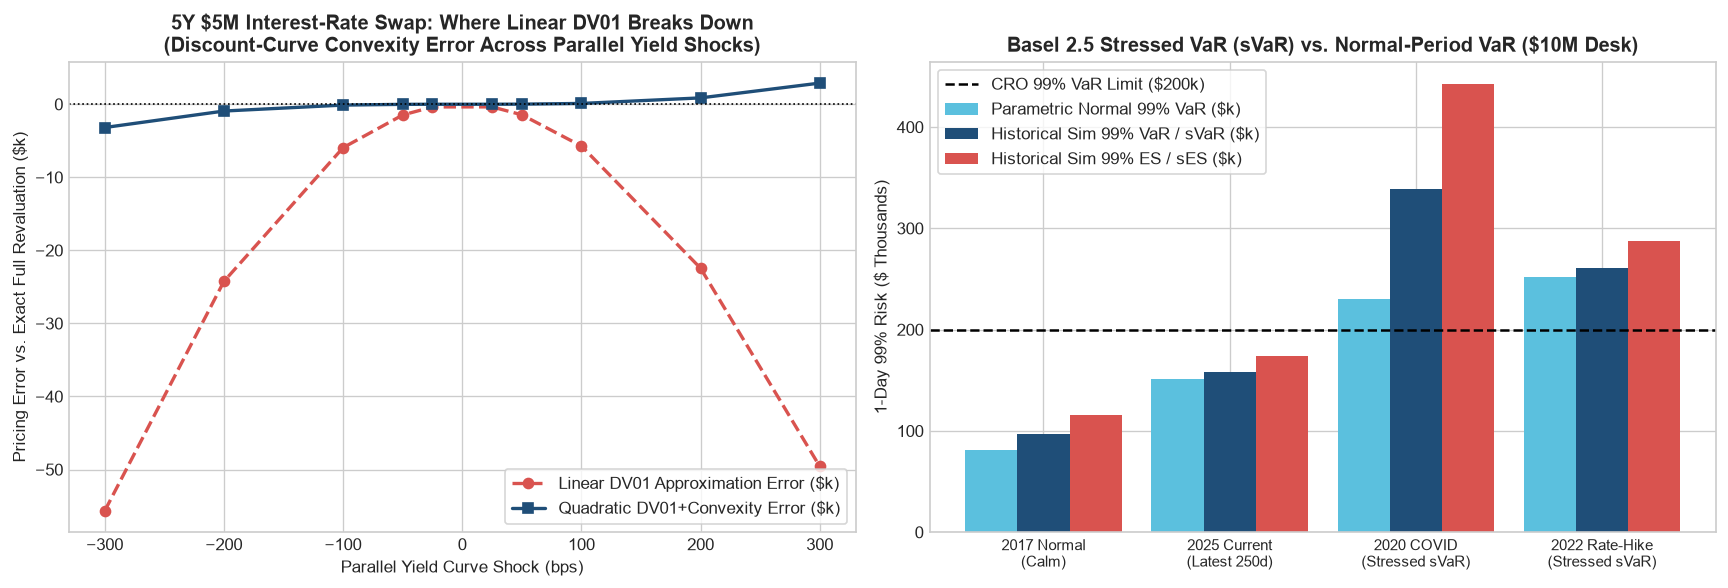

,Trading_Days,Mean_VIX,Ann_Portfolio_Vol_pct,Parametric_Normal_VaR_99_USD,Historical_Sim_VaR_99_USD,Historical_Sim_ES_99_USD,Stressed_to_Normal_VaR_Ratio
Regime_Window,,,,,,,
Normal Period (2017 Low-Vol Calm),253,11.36,5.66,80684.01,97075.31,115804.58,1.00
"Current Window (Latest 250d, 2025)",250,17.09,10.24,151353.73,158473.92,173658.09,1.63
Stressed Window A (2020 COVID-19 Crash),255,26.47,15.91,230331.08,338666.16,442361.32,3.49
Stressed Window B (2022 Rate-Hike Bear),253,22.86,16.82,251737.38,261257.27,287551.37,2.69


In [6]:
swap_df = evaluate_swap_approximation_breakdown(notional_usd=5_000_000.0)
svar_df = compute_stressed_var_comparison(arith_returns, vix_df, weights=core_weights, notional_usd=notional_usd)

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.0))

# Left Panel: 5Y Swap Approximation Error (Linear DV01 vs Full Revaluation)
axes[0].plot(swap_df["Yield_Shock_bps"], swap_df["Linear_DV01_Error_USD"] / 1e3, "o--", color="#d9534f", lw=2.0, label="Linear DV01 Approximation Error ($k)")
axes[0].plot(swap_df["Yield_Shock_bps"], swap_df["Quadratic_Error_USD"] / 1e3, "s-", color="#1f4e78", lw=2.0, label="Quadratic DV01+Convexity Error ($k)")
axes[0].axhline(0.0, color="black", lw=1.0, ls=":")
axes[0].set_title("5Y $5M Interest-Rate Swap: Where Linear DV01 Breaks Down\n(Discount-Curve Convexity Error Across Parallel Yield Shocks)", fontweight="bold")
axes[0].set_xlabel("Parallel Yield Curve Shock (bps)")
axes[0].set_ylabel("Pricing Error vs. Exact Full Revaluation ($k)")
axes[0].legend(frameon=True)

# Right Panel: Stressed VaR (sVaR) vs Normal-Period VaR
x_idx = np.arange(len(svar_df))
w_b = 0.28
axes[1].bar(x_idx - w_b, svar_df["Parametric_Normal_VaR_99_USD"] / 1e3, width=w_b, color="#5bc0de", label="Parametric Normal 99% VaR ($k)")
axes[1].bar(x_idx, svar_df["Historical_Sim_VaR_99_USD"] / 1e3, width=w_b, color="#1f4e78", label="Historical Sim 99% VaR / sVaR ($k)")
axes[1].bar(x_idx + w_b, svar_df["Historical_Sim_ES_99_USD"] / 1e3, width=w_b, color="#d9534f", label="Historical Sim 99% ES / sES ($k)")
axes[1].axhline(200.0, color="black", ls="--", lw=1.5, label="CRO 99% VaR Limit ($200k)")
axes[1].set_xticks(x_idx)
axes[1].set_xticklabels(["2017 Normal\n(Calm)", "2025 Current\n(Latest 250d)", "2020 COVID\n(Stressed sVaR)", "2022 Rate-Hike\n(Stressed sVaR)"], fontsize=9)
axes[1].set_title("Basel 2.5 Stressed VaR (sVaR) vs. Normal-Period VaR ($10M Desk)", fontweight="bold")
axes[1].set_ylabel("1-Day 99% Risk ($ Thousands)")
axes[1].legend(frameon=True)

plt.tight_layout()
plt.show()

svar_df.round(2)